# MLP y Regresión logística

En este jupyternotebook se va a entrenar por un lado una regresión logística y un MLP para comparar sus soluciones a la hora de diferenciar la señal del fondo en dos casos, uno con las variables solo PRI y otro con las variables PRI y DER. 

In [1]:
import numpy as np
import pandas as pd
# ----------------------------------
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
# -----------------------------------
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split
# -----------------------------------
import matplotlib.pyplot as plt

## Carga de datos

Para desarrollar tanto la regresión logística como el MLP se va a hacer uso de los tres csv . El de entrenamiento para entrenar, el de Ajuste para ajustar los hiperparámetros y el de Test para analizar el resultado final de cada modelo entrenado.

In [2]:
Entrenamiento = pd.read_csv("Entrenamiento.csv")
Ajuste = pd.read_csv("Ajuste.csv")
Test = pd.read_csv("Test.csv")

Estos csv ya se han sometido a una normalización y limpieza de datos (mirar el EDA), por lo que solo es necesario ajustar los parametros para poder manipularlos en los diferentes modelos.

Los valores -999 no son valores que se tengan que eliminar como ya se ha observado en el SOM, por tanto se van a convertir en valores nulos para que no condicionen los resultados.

In [3]:
Entrenamiento = Entrenamiento.replace(np.nan, 0)
Ajuste = Ajuste.replace(np.nan, 0)
Test = Test.replace(np.nan, 0)

Se va a intercambiar los valores de señal y fondo por 0 y 1 para que la matriz Y sea numérica

In [4]:
Entrenamiento['Label'] = Entrenamiento["Label"].replace({"s":1, "b":0}).astype(int)
Ajuste["Label"] = Ajuste["Label"].replace({"s":1, "b":0}).astype(int)
Test["Label"] = Test["Label"].replace({"s":1, "b":0}).astype(int)

# Regresión logística

## Preparación de datos

Como se ha descrito anteriormente, al regresión logística se va a calcular respecto de los dos subgrupos PRI y PRI + DER junto con las columna del label que dice si es fondo o señal y los pesos para el AMS.

In [5]:
Entrenamiento_DER = Entrenamiento.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])
Entrenamiento_PRI = Entrenamiento_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met","PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta","PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)
Y_E = Entrenamiento["Label"]
W_E = Entrenamiento["KaggleWeight"]

In [6]:
Ajuste_DER = Ajuste.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])
Ajuste_PRI = Ajuste_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met","PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta","PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)
Y_A = Ajuste["Label"]
W_A = Ajuste["KaggleWeight"]

In [7]:
Test_DER = Test.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])
Test_PRI = Test_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met","PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta","PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)
Y_T = Test["Label"]
W_T = Test["KaggleWeight"]

## Entrenamiento de la Regresión logística

La regresión logística es un modelo de aprendizaje supervisado lineal con una sola capa oculta.

In [8]:
def calcular_ams(y, prob, pesos, umbral):           # el AMS permite ver cómo de acertado fue (cuanto más alto mejor)
    c = 10
    seleccionados = prob >= umbral                  # Genera un vector true false, siendo true si el evento es cogido por señal, es decir pasa el filtro del umbral
    s = pesos[seleccionados & (y == 1)].sum()       # Suma la cantidad de eventos que sean señal tanto en el modelo como de verdad
    b = pesos[seleccionados & (y == 0)].sum()

    AMS = np.sqrt(2*((s+b+c)*np.log(1+(s/(b+c)))-s))
    return AMS

def buscar_mejor_umbral(y, prob, pesos):
    umbrales = np.quantile(prob, np.linspace(0.50, 0.99, 200))
    lista_ams = [calcular_ams(y, prob, pesos, u) for u in umbrales]
    mejor = np.argmax(lista_ams)
    return umbrales[mejor], lista_ams[mejor]

In [9]:
def regresion_logistica(Entrenamiento, Y_E, Ajuste, Y_A, W_A, Test, Y_T, W_T, C=np.inf):
    # 1) Entrenar (pasos 1-3 del pseudocódigo)
    modelo = LogisticRegression(solver="newton-cholesky", C=C, tol=1e-7, max_iter=20)   # Crea el modelo
    modelo.fit(Entrenamiento, Y_E)                  # Entrena hasta que deja de cambiar o max_iter

    print("Iteraciones:", modelo.n_iter_)           # cuántas vueltas dio el bucle
    print(modelo.intercept_, modelo.coef_)          # el vector β final: β₀ y β₁…β_d

    # 2) Elegir el umbral con el mejor AMS en VALIDACIÓN
    p_val = modelo.predict_proba(Ajuste)[:, 1]
    umbral, ams_val = buscar_mejor_umbral(Y_A, p_val, W_A)

    # 3) Aplicar ese umbral al TEST
    p_test = modelo.predict_proba(Test)[:, 1]
    ams_test = calcular_ams(Y_T, p_test, W_T, umbral)
    # auc_test = roc_auc_score(L_T, p_test, sample_weight = W_T)

    print(f"Umbral = {umbral:.3f} | AMS val = {ams_val:.3f} | AMS test = {ams_test:.3f}")
    return modelo, ams_test

In [10]:
modelo_pri, ams_pri = regresion_logistica(Entrenamiento_PRI, Y_E, Ajuste_PRI, Y_A, W_A, Test_PRI, Y_T, W_T)
modelo_der, ams_der = regresion_logistica(Entrenamiento_DER, Y_E, Ajuste_DER, Y_A, W_A, Test_DER, Y_T, W_T)

print(f"AMS PRI / AMS PRI+DER = {ams_pri / ams_der:.1%}")

Iteraciones: [4]
[-0.44785614] [[ 0.57123369 -0.00440606 -0.01019967 -0.21368881 -0.00151402  0.00378634
  -0.35406173  0.01067767  0.01582954 -0.28355078  0.34082926  0.00170435
   0.00075096 -0.23060109  0.00723793 -0.00837861  0.60880778]]
Umbral = 0.327 | AMS val = 1.641 | AMS test = 1.632
Iteraciones: [5]
[-1.45624949] [[ 2.60965978e-01 -4.16818121e-01 -7.48839411e-01  3.87911633e-02
   1.49214794e+00 -1.25215500e+00 -1.08513817e-01  7.38814344e-01
  -9.33243394e-02 -2.15106529e-01  8.65104009e+00  2.37747286e-01
   3.58271897e-01  7.65291570e+00 -2.66074461e-03 -5.36713422e-03
  -5.63358774e+00 -4.35387582e-03  5.74756816e-03 -1.01437206e-01
   3.35643363e-03 -7.08065924e-03 -1.51419194e-01  4.25185254e-01
   2.14100721e-04  6.27506492e-04  2.92990051e-01  8.23981447e-03
  -2.97550693e-03  4.32913421e-01  8.63984481e-01]]
Umbral = 0.435 | AMS val = 1.884 | AMS test = 1.897
AMS PRI / AMS PRI+DER = 86.0%


## Análisis de resultados

Resultados obtenidos:

| Modelo | Iteraciones | Umbral | AMS (Ajuste) | AMS (Test) |
| --- | --- | --- | --- | --- |
| PRI | 4 | 0.327 | 1.641 | 1.632 |
| PRI + DER | 5 | 0.435 | 1.884 | 1.879 |

El umbral óptimo se ha elegido maximizando el AMS en el conjunto de validación (Ajuste) y se ha aplicado sin cambios al conjunto de test. En ambos modelos, el AMS de test es prácticamente igual al de validación (1,632 frente a 1,641, y 1,879 frente a 1,860). Esto indica que el modelo y el umbral generalizan bien a eventos que no se han usado ni para entrenar ni para elegir el umbral, y que no hay sobreajuste.

Añadir las variables DER mejora el AMS de test de 1,632 a 1,879, es decir, un 15 % más. Las variables derivadas, calculadas por los físicos a partir de las primitivas, aportan información que un modelo lineal no puede extraer por sí solo de las variables PRI. Tiene sentido: muchas DER son combinaciones no lineales de las PRI (masas invariantes, cocientes, distancias angulares), y la regresión logística solo puede combinar las variables de forma lineal.

La hipótesis H1 planteaba que el AMS con solo variables PRI sería al menos el 90 % del AMS con todas las variables. Con la regresión logística se obtiene un 86.0 %, así que la hipótesis no se cumple para el modelo lineal.

Este resultado no es definitivo para H1, ya que la regresión logística es solo la línea base. El MLP, al poder aprender relaciones no lineales entre las variables, podría reconstruir parte de la información que aportan las DER a partir de las PRI. Si eso ocurre, el cociente debería acercarse al 90 %.

### Intepretación de los cocientes

Como las variables están normalizadas, el valor absoluto de cada coeficiente indica cuánto influye esa variable en la decisión del modelo, y el signo indica hacia dónde empuja (positivo hacia señal, negativo hacia fondo). Eso no supone que son las variables más determinantes o importantes del conjunto de variables. Además, los ángulos φ (PRI_tau_phi, PRI_lep_phi, PRI_met_phi …) tienen coeficientes casi nulos, entre 0,001 y 0,01. Esto es coherente con la física del problema: el detector es simétrico respecto al eje del haz, así que el ángulo azimutal de una partícula, por sí solo, no distingue la señal del fondo.

### Coeficientes del modelo solo PRI

Intercepto: β₀ = −0,726

| # | Variable | β | Tendencia | 
|---|---|---|---|
| 1 | PRI_tau_pt | 0,571 | hacia señal |
| 2 | PRI_tau_eta | −0,004 | ≈ sin influencia |
| 3 | PRI_tau_phi | −0,010 | ≈ sin influencia |
| 4 | PRI_lep_pt | −0,214 | hacia fondo |
| 5 | PRI_lep_eta | −0,002 | ≈ sin influencia |
| 6 | PRI_lep_phi | 0,004 | ≈ sin influencia |
| 7 | PRI_met | −0,354 | hacia fondo |
| 8 | PRI_met_phi | 0,011 | ≈ sin influencia |
| 9 | PRI_met_sumet | 0,016 | ≈ sin influencia |
| 10 | PRI_jet_num | −0,277 | hacia fondo |
| 11 | PRI_jet_leading_pt | 0,341 | hacia señal |
| 12 | PRI_jet_leading_eta | 0,002 | ≈ sin influencia |
| 13 | PRI_jet_leading_phi | 0,001 | ≈ sin influencia |
| 14 | PRI_jet_subleading_pt | −0,231 | hacia fondo |
| 15 | PRI_jet_subleading_eta | 0,007 | ≈ sin influencia |
| 16 | PRI_jet_subleading_phi | −0,008 | ≈ sin influencia |
| 17 | PRI_jet_all_pt | 0,609 | hacia señal |


### Coeficientes del modelo PRI + DER (con indicadora de DER_mass_MMC)

Intercepto: β₀ = −0,872

| # | Variable | β | Tendencia |
|---|---|---|---|
| 1 | DER_mass_MMC | 0,261 | hacia señal |
| 2 | DER_mass_transverse_met_lep | −0,417 | hacia fondo |
| 3 | DER_mass_vis | −0,749 | hacia fondo |
| 4 | DER_pt_h | 0,039 | ≈ sin influencia |
| 5 | DER_deltaeta_jet_jet | 1,492 | hacia señal |
| 6 | DER_mass_jet_jet | −1,252 | hacia fondo |
| 7 | DER_prodeta_jet_jet | −0,109 | hacia fondo |
| 8 | DER_deltar_tau_lep | 0,739 | hacia señal |
| 9 | DER_pt_tot | −0,093 | hacia fondo |
| 10 | DER_sum_pt | −0,215 | hacia fondo |
| 11 | DER_pt_ratio_lep_tau | 8,651 | hacia señal |
| 12 | DER_met_phi_centrality | 0,238 | hacia señal |
| 13 | DER_lep_eta_centrality | 0,358 | hacia señal |
| 14 | PRI_tau_pt | 7,653 | hacia señal |
| 15 | PRI_tau_eta | −0,003 | ≈ sin influencia |
| 16 | PRI_tau_phi | −0,005 | ≈ sin influencia |
| 17 | PRI_lep_pt | −5,634 | hacia fondo |
| 18 | PRI_lep_eta | −0,004 | ≈ sin influencia |
| 19 | PRI_lep_phi | 0,006 | ≈ sin influencia |
| 20 | PRI_met | −0,101 | hacia fondo |
| 21 | PRI_met_phi | 0,003 | ≈ sin influencia |
| 22 | PRI_met_sumet | −0,007 | ≈ sin influencia |
| 23 | PRI_jet_num | −0,148 | hacia fondo |
| 24 | PRI_jet_leading_pt | 0,425 | hacia señal |
| 25 | PRI_jet_leading_eta | 0,0002 | ≈ sin influencia |
| 26 | PRI_jet_leading_phi | 0,0006 | ≈ sin influencia |
| 27 | PRI_jet_subleading_pt | 0,293 | hacia señal |
| 28 | PRI_jet_subleading_eta | 0,008 | ≈ sin influencia |
| 29 | PRI_jet_subleading_phi | −0,003 | ≈ sin influencia |
| 30 | PRI_jet_all_pt | 0,433 | hacia señal |
| 31 | MMC_no_definida | 0,311 | hacia señal |

Se considera "≈ sin influencia" cuando |β| < 0,05.
El interceptor muestra hacia donde tiende el modelo en el inicio. Que sea negativo significa que tiende hacia el fondo, lo que se corresponde con el modelo ya que tiene más eventos de fondo que de señal.

# MLP

Definición y uso en este proyecto

## Preparación de datos

Se va diferencias dos grupos en entrenamiento, un 80% con el que se hará el entrenamiento y otro 20% para la validación

In [11]:
Entrenamiento, Validacion = train_test_split(Entrenamiento, test_size=0.2,stratify=Entrenamiento["Label"], random_state=42)

Sin embargo, esta estratificación supone que se tenga que hacer un ajuste en los pesos o kaggleweight de cada uno de los grupos:

In [12]:
def equilibrar(df):
    w = df["KaggleWeight"] / df.groupby("Label")["KaggleWeight"].transform("sum") * (len(df) / 2)
    return w.to_numpy()

Como el MLP se va a hacer respecto de PRI con PRI+DER se vuelven a separar tanto Entrenamiento como validación en otros dos subconjuntos:

In [13]:
# Entrenamiento DER / DER + PRI
Entrenamiento_DER = Entrenamiento.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])
Entrenamiento_PRI = Entrenamiento_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met","PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta","PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)

# Ya existen Y_E ("label en valores numéricos 0 1")
Y_E = Entrenamiento["Label"]
W_E = equilibrar(Entrenamiento)

In [14]:
Validacion_DER = Validacion.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])
Validacion_PRI = Validacion_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met","PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta","PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)

Y_V = Validacion["Label"]
W_V = equilibrar(Validacion)

In [15]:
# Comprobación de estratificación hecha de forma correcta

# 1. Tamaños: el primer número igual en cada grupo
print(Entrenamiento_PRI.shape, Entrenamiento_DER.shape, Y_E.shape, W_E.shape)
print(Validacion_PRI.shape,    Validacion_DER.shape,    Y_V.shape, W_V.shape)

# 2. Labels: solo 0 y 1, con ~34 % de señal
print(np.unique(Y_E), Y_E.mean())     # [0 1]  ~0.34
print(np.unique(Y_V), Y_V.mean())     # [0 1]  ~0.34

# 3. Pesos equilibrados y con media 1
print(W_E[Y_E == 1].sum(), W_E[Y_E == 0].sum())   # iguales
print(W_V[Y_V == 1].sum(), W_V[Y_V == 0].sum())   # iguales
print(W_E.mean(), W_V.mean())                     # 1.0  1.0

# 4. Sin valores que rompan el entrenamiento
for nombre, X in [("Entrenamiento_PRI", Entrenamiento_PRI), ("Entrenamiento_DER", Entrenamiento_DER),
                  ("Validacion_PRI", Validacion_PRI), ("Validacion_DER", Validacion_DER)]:
    print(nombre,
          "NaN:", np.isnan(X).sum(),            # 0
          "inf:", np.isinf(X).sum(),            # 0
          "-999:", (X == -999).sum(),           # 0
          "máx |x|:", np.abs(X).max().round(1)) # no enorme (< 10-20)

# 5. Estandarización (importante para ReLU)
print(Entrenamiento_DER.mean(axis=0).round(2))   # todos cerca de 0
print(Entrenamiento_DER.std(axis=0).round(2))    # todos cerca de 1

(200000, 17) (200000, 31) (200000,) (200000,)
(50000, 17) (50000, 31) (50000,) (50000,)
[0 1] 0.34267
[0 1] 0.34266
99999.99999999997 100000.0
25000.0 24999.999999999996
1.0 1.0
Entrenamiento_PRI NaN: PRI_tau_pt                0
PRI_tau_eta               0
PRI_tau_phi               0
PRI_lep_pt                0
PRI_lep_eta               0
PRI_lep_phi               0
PRI_met                   0
PRI_met_phi               0
PRI_met_sumet             0
PRI_jet_num               0
PRI_jet_leading_pt        0
PRI_jet_leading_eta       0
PRI_jet_leading_phi       0
PRI_jet_subleading_pt     0
PRI_jet_subleading_eta    0
PRI_jet_subleading_phi    0
PRI_jet_all_pt            0
dtype: int64 inf: PRI_tau_pt                0
PRI_tau_eta               0
PRI_tau_phi               0
PRI_lep_pt                0
PRI_lep_eta               0
PRI_lep_phi               0
PRI_met                   0
PRI_met_phi               0
PRI_met_sumet             0
PRI_jet_num               0
PRI_jet_leading_pt       

## Creación de perceptrones multicapa

Primero se van a generar las redes de cada uno de los grupos PRI y PRI + DER. Para poder determinar los hiperparámetros se van a a generar diferentes configuraciones. Para ello vamos a generalizar el siguiente código de creación de redes:

<img src="image.png" width="700">

Cada capa oculta estará configurada con activación ReLU ya que es más simple de ejecutar. Mientras que la capa de salida tendrá una única salida (una neurona) con activación sigmoidal, ya que se espera que la salida resulte en la probabilidad de señal para más tarde servirá para calcular el ams y poder comparar tanto los hiperparámetros más óptimos como la comparación entre el modelo PRI (modelo_PRI) y el del modelo PRI+DER (modelo_DER) de cada configuración.

In [26]:
# Generalización del código

def creacion_red(shape_input, num_neuronas, dropout = 0):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    capas = [tf.keras.layers.Input(shape=(shape_input,))]

    for n in num_neuronas:
        capas.append(tf.keras.layers.Dense(n, activation="relu", kernel_initializer="he_normal"))
        if dropout > 0:
            capas.append(tf.keras.layers.Dropout(dropout))

    capas.append(tf.keras.layers.Dense(1, activation="sigmoid"))  

    return tf.keras.Sequential(capas)

La configuración de la cantidad de neuronas por capa oculta de cada red de entrenamiento se va a configurar de manera que haya una proporción de tamaño entre las redes creadas para que la comparación entre redes tenga sentido por la relación de tamaño que guardan entre si:

| Configuración | Capas ocultas | Dropout | Relación |
| --- | --- | --- | --- |
| 1 | 64 (1 capa) | - | Menos profundidad |
| 2 | 32, 16 (2 capas) | - | Más pequeña |
| 3 | 64, 32 (2 capas) | - | REFERENCIA |
| 4 | 128, 64 (2 capas) | - | Más ancha |
| 5 | 128, 64, 32 (3 capas) | - | Más profunda |
| 6 | La mejor entre la 1 - 5 | 0.2 | Con dropout |


In [27]:
modelos = {}

### Red (64)

Van a seguir un modelo de una capa oculta con 64 neuronas.

In [28]:
modelos["MLP_64_PRI"] = creacion_red(Entrenamiento_PRI.shape[1], [64])
modelos["MLP_64_DER"] = creacion_red(Entrenamiento_DER.shape[1], [64])

### Red (32,16)

Van a seguir un modelo con dos capas ocultas de 32 y 16 neuronas

In [29]:
modelos["MLP_32_16_PRI"] = creacion_red(Entrenamiento_PRI.shape[1], [32,16])
modelos["MLP_32_16_DER"] = creacion_red(Entrenamiento_DER.shape[1], [32,16])

### Red (64,32)

Van a seguir un modelo de dos capas ocultas con 64 y 32 neuronas.

In [30]:
modelos["MLP_64_32_PRI"] = creacion_red(Entrenamiento_PRI.shape[1], [64,32])
modelos["MLP_64_32_DER"] = creacion_red(Entrenamiento_DER.shape[1], [64,32])

### Red (128,64)

Van a seguir un modelo de dos capas ocultas con 64 y 32 neuronas.

In [31]:
modelos["MLP_128_64_PRI"] = creacion_red(Entrenamiento_PRI.shape[1], [128,64])
modelos["MLP_128_64_DER"] = creacion_red(Entrenamiento_DER.shape[1], [128,64])

### Red (128,64,32)

Van a seguir un modelo de tres capas ocultas con 128, 64 y 32 neuronas.

In [32]:
modelos["MLP_128_64_32_PRI"] = creacion_red(Entrenamiento_PRI.shape[1], [128,64,32])
modelos["MLP_128_64_32_DER"] = creacion_red(Entrenamiento_DER.shape[1], [128,64,32])

## Entrenamiento del MLP con ReLU

Una vez creados se van a establecer los parámetros de aprendizaje con una tasa de aprendizaje de 0.001 y de pérdida basada en la entropía cruzada binaria, ya que se basa en unos modelos con salida sigmoidal. Además, de va a determinar las condiciones de parada.

In [33]:
# 1. Compilar para modelo_PRI y modelo_DER (modelo==red)
def aprendizaje(modelo):
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        weighted_metrics=[tf.keras.metrics.AUC(name="auc")]
    )

# 2. Criterio de parada para ambos el mismo, ya que al final se desean comparar los resultados.
parada = tf.keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience = 10,                  # máx épocas seguidas sin mejorar
    restore_best_weights=True
)

Generalizando el entrenamiento para cualquier modelo

In [34]:
# Entrenamiento de ambos MLP
def entrenar(Entrenamiento, modelo, Y_E, W_E, Validacion, Y_V, W_V):

    aprendizaje(modelo)

    historial = modelo.fit(
        Entrenamiento, Y_E,
        sample_weight = W_E,
        validation_data = (Validacion, Y_V, W_V),
        epochs = 100,                                   # máx iteraciones de entrenamiento
        batch_size = 512,                               # Número de eventos que se procesan antes de cada actualización de pesos
        callbacks = [parada],
        verbose = 2
    )

    return historial

In [35]:
redes = ["MLP_64", "MLP_64_32", "MLP_32_16", "MLP_128_64", "MLP_128_64_32"]
historiales = {}

for red in redes:
    historiales[red + "_PRI"] = entrenar(Entrenamiento_PRI, modelos[red + "_PRI"], Y_E, W_E, Validacion_PRI, Y_V, W_V)
    historiales[red + "_DER"] = entrenar(Entrenamiento_DER, modelos[red + "_DER"], Y_E, W_E, Validacion_DER, Y_V, W_V)

Epoch 1/100
391/391 - 3s - 8ms/step - auc: 0.8085 - loss: 0.5347 - val_auc: 0.8566 - val_loss: 0.4733
Epoch 2/100
391/391 - 1s - 3ms/step - auc: 0.8667 - loss: 0.4573 - val_auc: 0.8713 - val_loss: 0.4490
Epoch 3/100
391/391 - 1s - 3ms/step - auc: 0.8768 - loss: 0.4402 - val_auc: 0.8772 - val_loss: 0.4390
Epoch 4/100
391/391 - 1s - 3ms/step - auc: 0.8810 - loss: 0.4328 - val_auc: 0.8800 - val_loss: 0.4342
Epoch 5/100
391/391 - 1s - 4ms/step - auc: 0.8834 - loss: 0.4288 - val_auc: 0.8819 - val_loss: 0.4310
Epoch 6/100
391/391 - 1s - 3ms/step - auc: 0.8851 - loss: 0.4257 - val_auc: 0.8834 - val_loss: 0.4284
Epoch 7/100
391/391 - 3s - 7ms/step - auc: 0.8866 - loss: 0.4231 - val_auc: 0.8847 - val_loss: 0.4262
Epoch 8/100
391/391 - 1s - 4ms/step - auc: 0.8880 - loss: 0.4207 - val_auc: 0.8858 - val_loss: 0.4241
Epoch 9/100
391/391 - 1s - 3ms/step - auc: 0.8892 - loss: 0.4186 - val_auc: 0.8868 - val_loss: 0.4223
Epoch 10/100
391/391 - 1s - 3ms/step - auc: 0.8903 - loss: 0.4166 - val_auc: 0.887

El historial solo sirve si se quiere ver las gráficas de aprendizaje (pensar si se quieren poner)

## Ajuste de hiperparámetros

Para saber cual es el modelo más adecuado se van a comparar el AMS resultante de cada modelo para saber cuál es el mejor.

In [36]:
def calcular_ams(y, prob, pesos, umbral):           # el AMS permite ver cómo de acertado fue (cuanto más alto mejor)
    c = 10
    seleccionados = prob >= umbral                  # Genera un vector true false, siendo true si el evento es cogido por señal, es decir pasa el filtro del umbral
    s = pesos[seleccionados & (y == 1)].sum()       # Suma la cantidad de eventos que sean señal tanto en el modelo como de verdad
    b = pesos[seleccionados & (y == 0)].sum()

    AMS = np.sqrt(2*((s+b+c)*np.log(1+(s/(b+c)))-s))
    return AMS

def buscar_mejor_umbral(y, prob, pesos):
    umbrales = np.quantile(prob, np.linspace(0.50, 0.99, 200))
    lista_ams = [calcular_ams(y, prob, pesos, u) for u in umbrales]
    mejor = np.argmax(lista_ams)
    return umbrales[mejor], lista_ams[mejor]

El calculo de las probabilidades que saca cada modelo se hará con el conjunto de Ajuste, que ya se preparó en la preparación de datos del apartado de Regresión logística. Por tanto ya se tiene los valores de Ajuste tanto de PRI como de PRI+DER, la etiquetas de Y_A y los pesos W_A. Por ello se va a pasar a calcular las probabilidades que sacaría cada red y su AMS.

In [39]:
redes = ["MLP_64", "MLP_32_16", "MLP_64_32", "MLP_128_64", "MLP_128_64_32"]

for red in redes:
    p_PRI = modelos[red + "_PRI"].predict(Ajuste_PRI).ravel()
    p_DER = modelos[red + "_DER"].predict(Ajuste_DER).ravel()
    print(f"{red}: AMS PRI = {buscar_mejor_umbral(Y_A, p_PRI, W_A)} | AMS DER = {buscar_mejor_umbral(Y_A, p_DER, W_A)}")

3125/3125 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
MLP_64: AMS PRI = (np.float64(0.888950044545696), np.float64(2.600373765913635)) | AMS DER = (np.float64(0.9366002293417801), np.float64(3.607980261702401))
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
MLP_32_16: AMS PRI = (np.float64(0.9195258493040075), np.float64(2.8599184252420486)) | AMS DER = (np.float64(0.9345901021346374), np.float64(3.5725357655979404))
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
MLP_64_32: AMS PRI = (np.float64(0.9281052938118652), np.float64(3.0225462114019392)) | AMS DER = (np.float64(0.9407095188980726), np.float64(3.5272467650206702))
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
MLP_128_64: AMS PRI = (np.float64(0.9102322294484431), np.float64(2.814905603200631)) | AMS DER = (np.float64(0.9354584463038037), np.float64(3.493917145414097))
3125/3125 ━

| Modelo | AMS PRI | AMS PRI + DER |
| --- | --- | --- |
| MLP_64 | 2.6 | **3.61** |
| MLP_32_16 | 2.86 | 3.57 |
| MLP_64_32 | **3.02** | 3.53 |
| MLP_128_64 | 2.81 | 3.49 |
| MLP_128_64_32 | 2.77 | 3.5 |

Por tanto, el mejor hiperparámetro de configuración para los valores de PRI será el del MLP con dos capas ocultas con 64 y 32 neuronas y para los valores de PRI+DER será el MLP con una capa oculta de 64 neuronas.

No obstante, falta compararlos con y sin dropout

In [41]:
MLP_64_32_PRI_drop = creacion_red(Entrenamiento_PRI.shape[1], [64,32], 0.2)
MLP_64_DER_drop = creacion_red(Entrenamiento_DER.shape[1], [64], 0.2)

In [42]:
entrenar(Entrenamiento_PRI, MLP_64_32_PRI_drop, Y_E, W_E, Validacion_PRI, Y_V, W_V)
entrenar(Entrenamiento_DER, MLP_64_DER_drop, Y_E, W_E, Validacion_DER, Y_V, W_V)

Epoch 1/100
391/391 - 5s - 12ms/step - auc: 0.7975 - loss: 0.5496 - val_auc: 0.8588 - val_loss: 0.4689
Epoch 2/100
391/391 - 2s - 5ms/step - auc: 0.8506 - loss: 0.4792 - val_auc: 0.8721 - val_loss: 0.4472
Epoch 3/100
391/391 - 2s - 5ms/step - auc: 0.8621 - loss: 0.4625 - val_auc: 0.8789 - val_loss: 0.4365
Epoch 4/100
391/391 - 2s - 6ms/step - auc: 0.8680 - loss: 0.4537 - val_auc: 0.8824 - val_loss: 0.4306
Epoch 5/100
391/391 - 2s - 5ms/step - auc: 0.8718 - loss: 0.4473 - val_auc: 0.8849 - val_loss: 0.4260
Epoch 6/100
391/391 - 4s - 9ms/step - auc: 0.8746 - loss: 0.4429 - val_auc: 0.8866 - val_loss: 0.4232
Epoch 7/100
391/391 - 5s - 13ms/step - auc: 0.8766 - loss: 0.4399 - val_auc: 0.8877 - val_loss: 0.4210
Epoch 8/100
391/391 - 3s - 7ms/step - auc: 0.8789 - loss: 0.4357 - val_auc: 0.8884 - val_loss: 0.4197
Epoch 9/100
391/391 - 3s - 7ms/step - auc: 0.8801 - loss: 0.4336 - val_auc: 0.8895 - val_loss: 0.4180
Epoch 10/100
391/391 - 3s - 8ms/step - auc: 0.8814 - loss: 0.4317 - val_auc: 0.8

In [ ]:
p_PRI = MLP_64_32_PRI_drop.predict(Ajuste_PRI).ravel()
print(f" MLP_64_32_PRI_drop: AMS = {buscar_mejor_umbral(Y_A, p_PRI, W_A)}")

p_DER = MLP_64_DER_drop.predict(Ajuste_DER).ravel()
print(f"MLP_64_DER_drop: AMS= {buscar_mejor_umbral(Y_A, p_DER, W_A)}")

3125/3125 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step
 MLP_64_32_PRI_drop: AMS = (np.float64(0.9179141964385258), np.float64(2.9518711506040627))
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step
MLP_64_DER_drop: AMS= (np.float64(0.9378501949058705), np.float64(3.5117034215475242))


| Modelo | AMS sin dropout | AMS con dropout | 
| --- | --- | --- |
| PRI | **3.02** | 2.95 |
| DER | **3.61** | 3.51 |

Por tanto se concluye que los mejores hiperparámetros para los valores del PRI es un modelo MLP con dos capas ocultas de 64 y 32 neuronas sin dropout. Y para los valores de PRI+DER un modelo MLP con una capa oculta de 64 neuronas sin dropout.

## Análisis del aprendizaje

Pero solo del modelo que se decida como el más óptimo

In [46]:
print(historiales["MLP_64_32_PRI"].history.keys())
print(historiales["MLP_64_DER"].history.keys())

dict_keys(['auc', 'loss', 'val_auc', 'val_loss'])
dict_keys(['auc', 'loss', 'val_auc', 'val_loss'])


In [47]:
def curvas_aprendizaje(historial, titulo, archivo=None):
    h = historial.history
    epocas = range(1, len(h["loss"]) + 1)
    mejor = np.argmin(h["val_loss"]) + 1

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    ax1.plot(epocas, h["loss"],     color="#2a6fdb", linewidth=2, label="Entrenamiento")
    ax1.plot(epocas, h["val_loss"], color="#e07a1f", linewidth=2, label="Validación")
    ax1.axvline(mejor, color="gray", linestyle="--", linewidth=1, label=f"Mejor época ({mejor})")
    ax1.set_xlabel("Época")
    ax1.set_ylabel("Pérdida (entropía cruzada)")
    ax1.set_title("Pérdida")
    ax1.legend()

    ax2.plot(epocas, h["auc"],     color="#2a6fdb", linewidth=2, label="Entrenamiento")
    ax2.plot(epocas, h["val_auc"], color="#e07a1f", linewidth=2, label="Validación")
    ax2.axvline(mejor, color="gray", linestyle="--", linewidth=1)
    ax2.set_xlabel("Época")
    ax2.set_ylabel("AUC")
    ax2.set_title("AUC")
    ax2.legend()

    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle(titulo)
    fig.tight_layout()

ANÁLISIS MODELADO PRI

Épocas entrenadas: 100


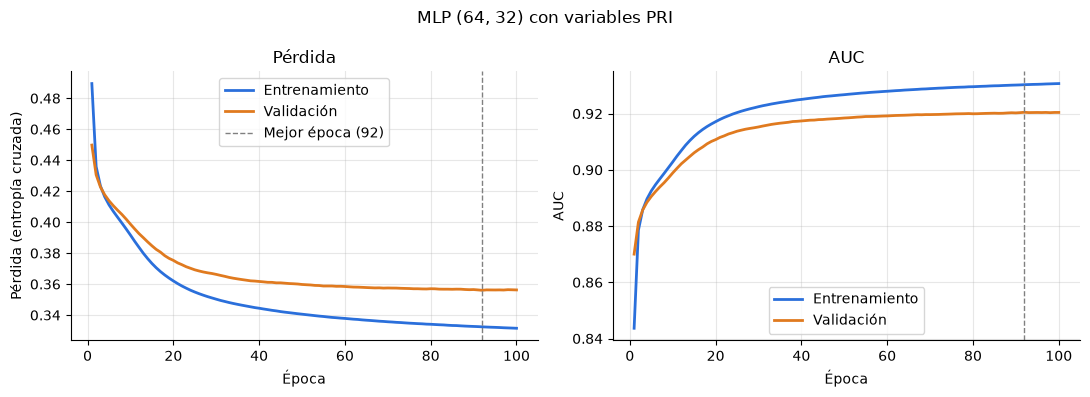

In [48]:
analisis_PRI = historiales["MLP_64_32_PRI"].history
print("ANÁLISIS MODELADO PRI\n")
print("Épocas entrenadas:", len(analisis_PRI["loss"]))
curvas_aprendizaje(historiales["MLP_64_32_PRI"], "MLP (64, 32) con variables PRI", "curvas_MLP_PRI.png")

ANÁLSISI MODELADO PRI+DER

Épocas entrenadas: 100


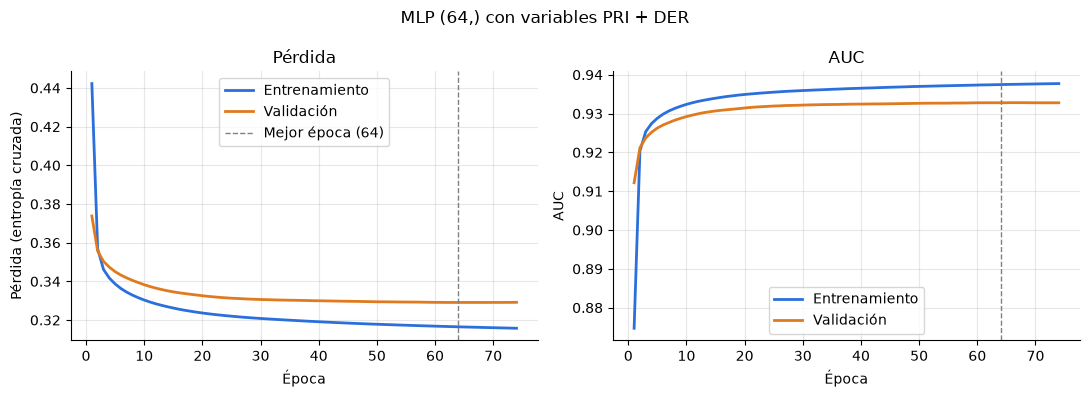

In [49]:
analisis_DER = historiales["MLP_64_DER"].history
print("ANÁLSISI MODELADO PRI+DER\n")
print("Épocas entrenadas:", len(analisis_PRI["loss"]))
curvas_aprendizaje(historiales["MLP_64_DER"], "MLP (64,) con variables PRI + DER", "curvas_MLP_PRIDER.png")

## Comprobación de H1

Una vez establecido los hiperparámetros, se va a comprobar la H1 calculando lo AMS con los subgrupos de Test para PRI y para PRI + DER

In [50]:
mejor_PRI = modelos["MLP_64_32_PRI"]
mejor_DER = modelos["MLP_64_DER"]
umbral_PRI = 0.9281052938118652
umbral_DER = 0.9366002293417801

p_PRI = mejor_PRI.predict(Test_PRI).ravel()
p_DER = mejor_DER.predict(Test_DER).ravel()

14063/14063 ━━━━━━━━━━━━━━━━━━━━ 26s 2ms/step
14063/14063 ━━━━━━━━━━━━━━━━━━━━ 26s 2ms/step


In [51]:
def calcular_ams(y, prob, pesos, umbral):           # el AMS permite ver cómo de acertado fue (cuanto más alto mejor)
    c = 10
    seleccionados = prob >= umbral                  # Genera un vector true false, siendo true si el evento es cogido por señal, es decir pasa el filtro del umbral
    s = pesos[seleccionados & (y == 1)].sum()       # Suma la cantidad de eventos que sean señal tanto en el modelo como de verdad
    b = pesos[seleccionados & (y == 0)].sum()

    AMS = np.sqrt(2*((s+b+c)*np.log(1+(s/(b+c)))-s))
    return AMS

In [52]:
ams_test_PRI = calcular_ams(Y_T, p_PRI, W_T, umbral_PRI)
ams_test_DER = calcular_ams(Y_T, p_DER, W_T, umbral_DER)

print(f"AMS test PRI     = {ams_test_PRI:.3f}")
print(f"AMS test PRI+DER = {ams_test_DER:.3f}")
print(f"AMS PRI / AMS PRI+DER = {ams_test_PRI / ams_test_DER:.1%}")

AMS test PRI     = 2.952
AMS test PRI+DER = 3.524
AMS PRI / AMS PRI+DER = 83.8%


Ver si se puede hacer con tres semillas y hacer conclusion de H1